In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from scipy.stats import iqr


In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')


In [4]:
print(f"data size is {df.shape}")
print(f"\ncolumns are {list(df.columns)}")
print(f"\n{df.dtypes}") 
print(f"\nnumber of unique values in each column\n{df.nunique()}")

print(f"\nnumeric continuous variables are : price, stars,reviews,")
print(f"\nnumeric discrete variables are : boughtInLastMonth ")
print(f"\ncategorical variables are : category")
print(f"\nbinary categorical variable is isBestSeller")


data size is (2443651, 9)

columns are ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

number of unique values in each column
uid                  2443651
asin                 2222742
title                2077591
stars                     42
reviews                19446
price                  82916
isBestSeller               2
boughtInLastMonth         25
category                 296
dtype: int64

numeric continuous variables are : price, stars,reviews,

numeric discrete variables are : boughtInLastMonth 

categorical variables are : category

binary categorical variable is isBestSeller


##### insight--> the best-seller distribution is dependent of the product category, but their association is weak

In [5]:
df.head(2)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers


In [6]:

crosstable_categoy_bestseller = pd.crosstab(index=df['category'],columns=df['isBestSeller'],margins='All')
crosstable_categoy_bestseller

isBestSeller,False,True,All
category,,,
3D Printers,247,1,248
3D Printing & Scanning,4065,2,4067
Abrasive & Finishing Products,245,5,250
Action Cameras,1696,1,1697
Adapters,251,3,254
...,...,...,...
Window Treatments,234,5,239
Women,17559,213,17772
Women's Sports & Outdoor Shoes,1939,20,1959


In [7]:
# normalized_crosstab--> category vs isBestSeller

crosstable_normalized = pd.crosstab(index=df['category'],columns=df['isBestSeller'],normalize='index')
crosstable_normalized_5= crosstable_normalized.sort_values(by=True,ascending=False).head(5)
crosstable_normalized_5


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339


In [8]:

# H0: category and bestseller status is independent
# H1: Category and Bestseller status are associated.

res = chi2_contingency(crosstable_categoy_bestseller)
res.statistic,res.pvalue

# res.statistic measures the overall difference between observed counts (your real table) and expected counts (what we’d see if category and bestseller were independent).
# the statistic is large, meaning observed counts are far from expected
# P-value is the probablity of observing the statistic at least this large if H0 is true
# p value < 0.05, reject H0


# ****** conclusion: bestseller status is not indenpent of category ****# 


(np.float64(36540.202700613874), np.float64(0.0))

In [9]:
association(crosstable_categoy_bestseller,method='cramer')

# ****** the strength of the assocation is relatively small ******

0.04323354945446208

<Axes: xlabel='isBestSeller', ylabel='category'>

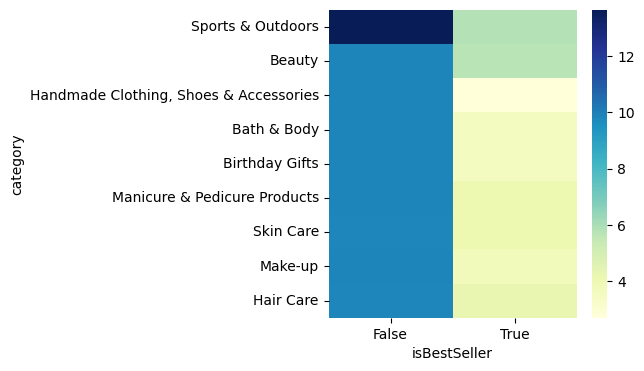

In [10]:
# frequency heatmap---> category vs isBestSeller 

crosstable_categoy_bestseller_10 = crosstable_categoy_bestseller.sort_values(by='All',ascending=False).head(10)
crosstable_categoy_bestseller_10 = crosstable_categoy_bestseller_10.copy()
crosstable_categoy_bestseller_10 = crosstable_categoy_bestseller_10.drop('All',axis=0).drop('All',axis=1)
crosstable_categoy_bestseller_10_log = np.log1p(crosstable_categoy_bestseller_10)

plt.figure(figsize=(4, 4))
sns.heatmap(
    crosstable_categoy_bestseller_10_log,       
    annot=False,            # do not show counts on the heatmap
    cmap="YlGnBu"          # color palette
)


##### Exploring Product Prices and Ratings Across Categories and Brands

In [11]:
# identify outliers in price using histogram + IQR (Interquartile Range) method
## first visualize, outliers exist
# sns.histplot(df['price'],bins=30)
# plt.show()
## then, IQR method
price_IQR = iqr(df['price'])
price_Q1 = df['price'].quantile(0.25) 
price_Q3 = df['price'].quantile(0.75) 
price_lower = price_Q1 - 1.5*price_IQR
price_upper = price_Q3 + 1.5*price_IQR
## remove price outliers
df_noPriceOutliers = df[~((df['price'] < price_lower)|(df['price'] > price_upper))]


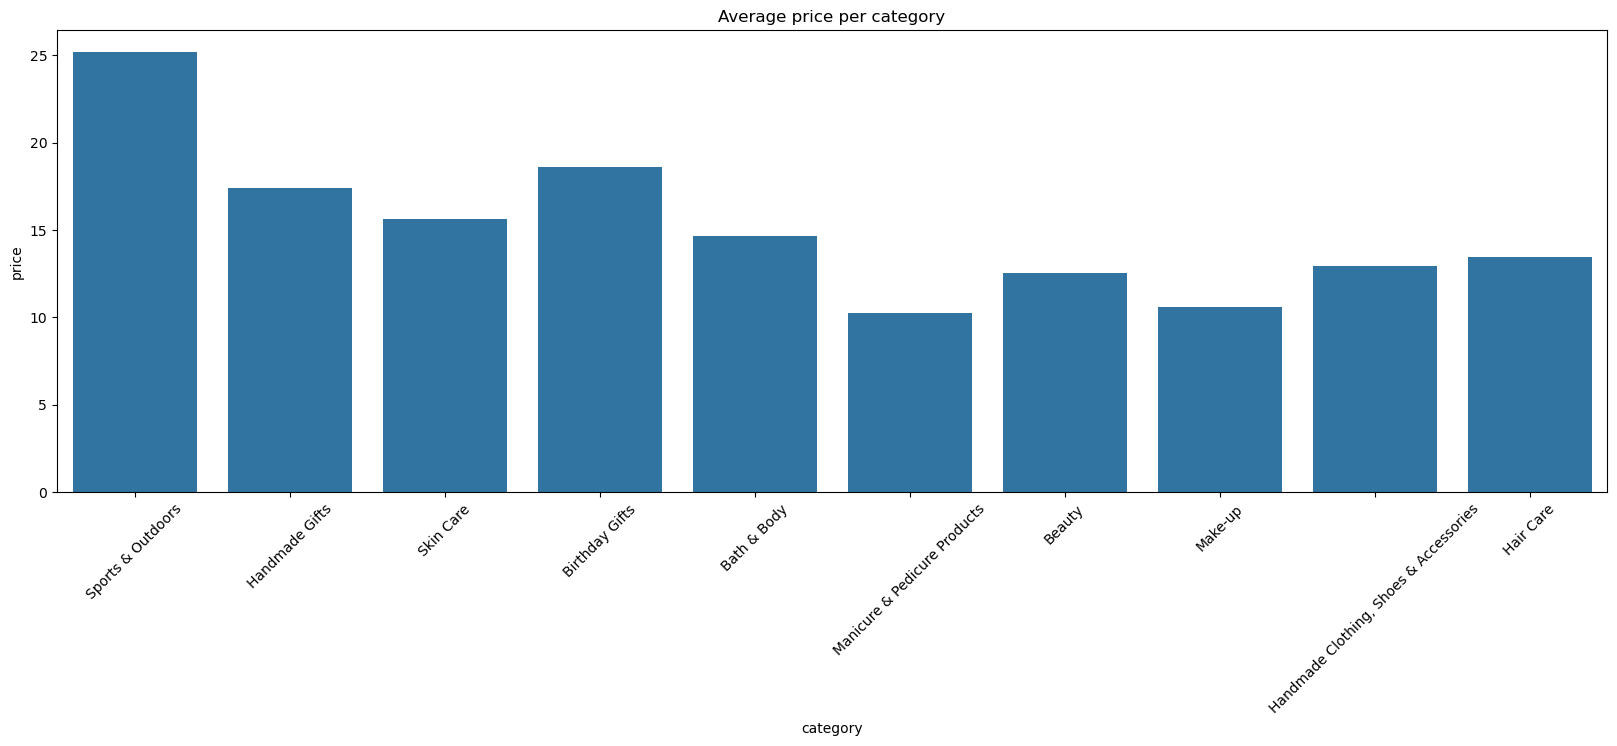

In [12]:
# make bar plot
# sport & outdoors, birthday gifts, handmade gifts have highest average price 
top_10_categories = list(df_noPriceOutliers['category'].value_counts().head(10).index)
top_10_categories 

df_noPriceOutliers_10 = df_noPriceOutliers[df_noPriceOutliers['category'].isin(top_10_categories)]

plt.figure(figsize=(20,6))
sns.barplot(data = df_noPriceOutliers_10, x = 'category',
            y = 'price',estimator='mean',errorbar=None)
plt.xticks(rotation = 45)
plt.title('Average price per category')
plt.show()



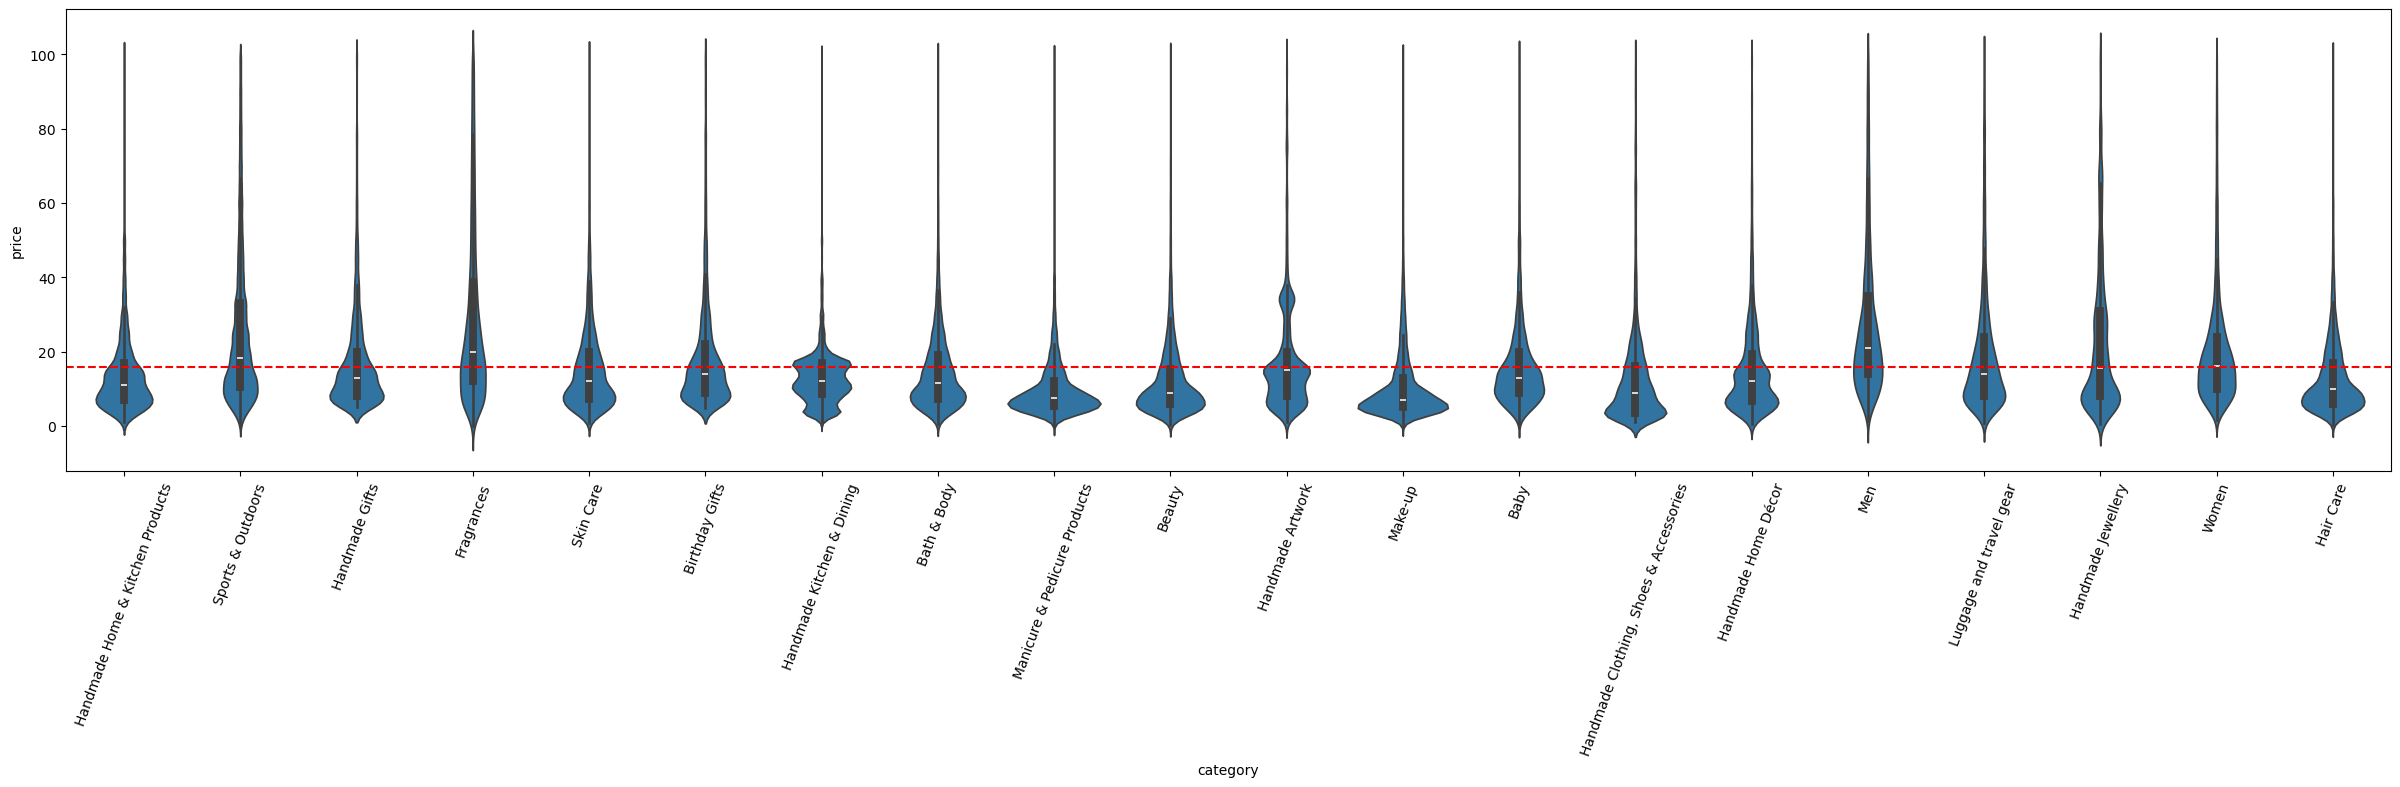

In [13]:
#**Violin Plots**:

top_20_categories = list(df_noPriceOutliers['category'].value_counts().head(20).index)
 

df_noPriceOutliers_20 = df_noPriceOutliers[df_noPriceOutliers['category'].isin(top_20_categories)]
global_median = df_noPriceOutliers_20['price'].median() 

plt.figure(figsize=(30,6))
sns.violinplot(data = df_noPriceOutliers_20, x = 'category',y = 'price')
plt.xticks(rotation = 70)
plt.axhline(y=global_median,color='red',linestyle = '--', label = f"median={global_median}")
plt.show()

# categories such as sport&outdoors, frgrances , men, women tend to have highest median compared to other categories

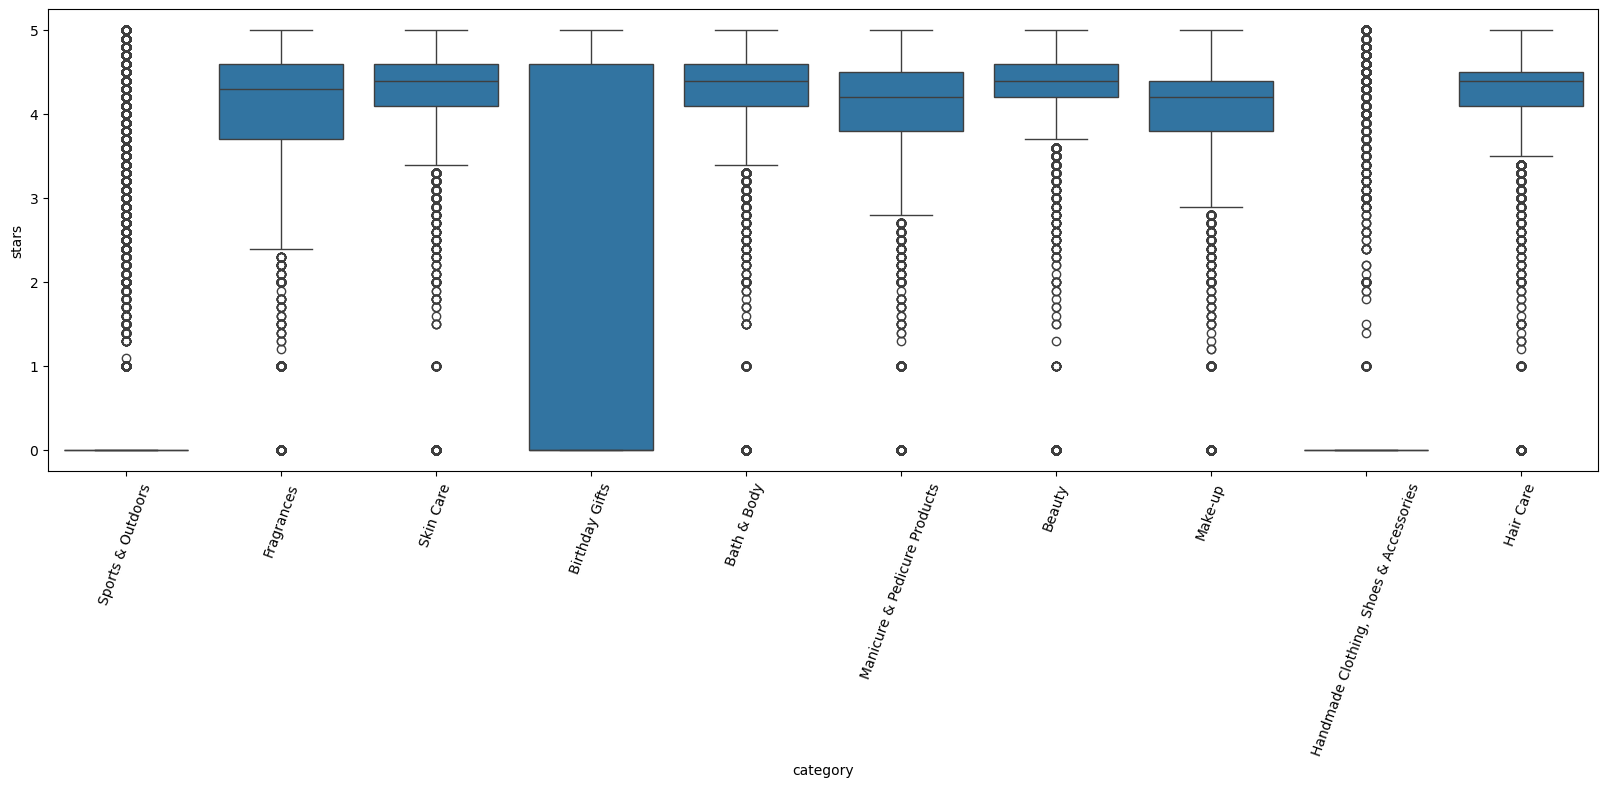

In [ ]:
# top 10 categories 

top10_categories = list(df['category'].value_counts().head(10).index)

df_top10_categories = df[df['category'].isin(top10_categories)]
df_top10_categories

plt.figure(figsize=(20,6))
sns.boxplot(data = df_top10_categories,x = 'category',y='stars')
plt.xticks(rotation=70)
plt.show()

# hair care, beauty, bath & body, skin care tend to receive highest median rating
# sport & outdoors, handmade , most of the ratings are 0 

#### Product Price and Rating

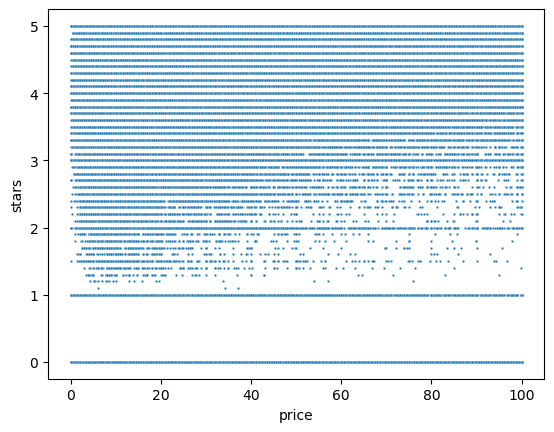

In [ ]:
sns.scatterplot(data=df_noPriceOutliers,x='price',y='stars',s=3)
plt.show()

# as price increases, the range of stars tend to decrease
# lower price (below 20) tend to have more lower rating , higher prce (above 40) tend to have more high rating fewer low rating

In [ ]:
# calculate correlation coefficient 

df_noPriceOutliers['stars'].corr(df_noPriceOutliers['price'],method = 'spearman')

# there is no siginficant correlation between price and rating


np.float64(-0.06679697280768325)

#### Use a correlation heatmap to visualize correlations between all numerical variables.

1. before removing reviews and stars 0.0, reviews and rating have a positive strong relatinoship 0.89
2. after removing  reviews and stars 0.0, reviews and rating have no correlation -0.17

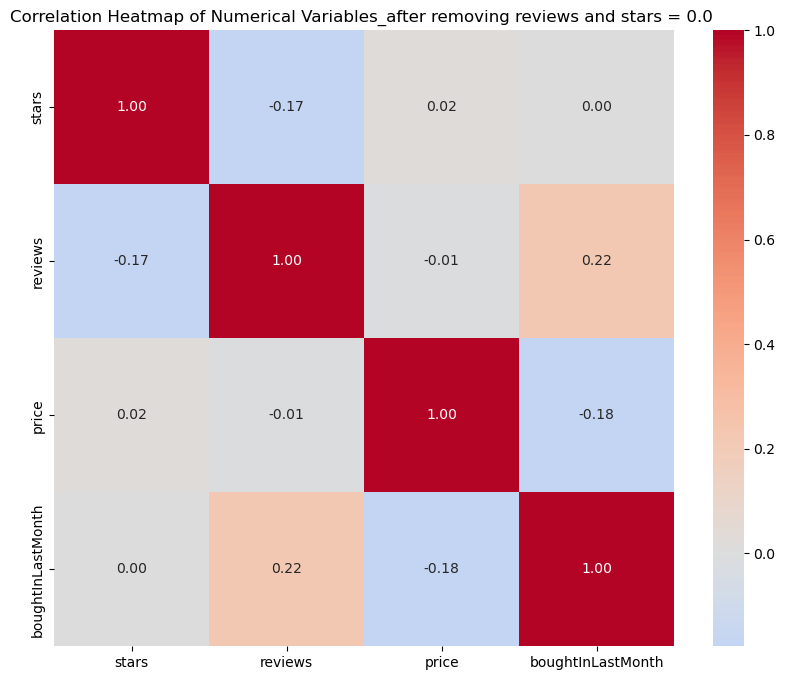

In [91]:
# checks before plotting
df_noPriceOutliers.dtypes, df_noPriceOutliers.isna().sum()

# removes outliers in reviews before plotting

reviews_IQR = iqr(df_noPriceOutliers['reviews'])
reivew_Q1 = df_noPriceOutliers['reviews'].quantile(0.25) 
reivew_Q3 = df_noPriceOutliers['reviews'].quantile(0.75) 
reivew_lower = reivew_Q1 - 1.5*reviews_IQR
reivew_upper = reivew_Q3 + 1.5*reviews_IQR

df_noPriceOutliers_noReviewOutliers = df_noPriceOutliers[~((df_noPriceOutliers['reviews'] < reivew_lower)|(df_noPriceOutliers['reviews'] > reivew_upper))]

df_noPriceOutliers_noReviewOutliers = df_noPriceOutliers_noReviewOutliers[~(df_noPriceOutliers_noReviewOutliers['reviews']==0)]


# df with only numeric variables 

numeric_cols = ['stars','reviews','price','boughtInLastMonth']
numeric_df = df_noPriceOutliers_noReviewOutliers[numeric_cols]
corr = numeric_df.corr(method = 'spearman')


plt.figure(figsize=(10,8))
sns.heatmap(
    corr,
    annot=True,        # show numbers inside cells
    fmt=".2f",         # format to 2 decimals
    cmap="coolwarm",   # color map
    center=0
)
plt.title("Correlation Heatmap of Numerical Variables_after removing reviews and stars = 0.0 ")
plt.show()
